Training Done! Q-Table learned.
Optimal Path Found: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]


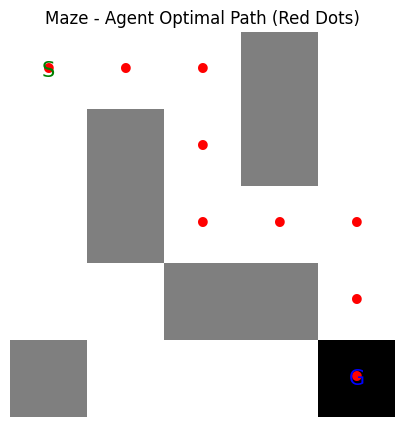

In [47]:
# SINGLE CELL - Reinforcement Learning Maze
import numpy as np
import matplotlib.pyplot as plt
import random

# 1. Create Simple Maze - 5x5 grid
# 0 = free path, 1 = wall, 2 = goal
maze = np.array([
    [0, 0, 0, 1, 0],
    [0, 1, 0, 1, 0],
    [0, 1, 0, 0, 0],
    [0, 0, 1, 1, 0],
    [1, 0, 0, 0, 2]  # 2 is Goal
])

# 2. Q-Learning Setup
n_rows, n_cols = maze.shape
q_table = np.zeros((n_rows, n_cols, 4)) # 4 actions: 0=Up, 1=Down, 2=Left, 3=Right
actions = [(-1,0), (1,0), (0,-1), (0,1)] # moves

alpha = 0.1  # learning rate
gamma = 0.9  # discount factor
epsilon = 0.2 # exploration

# 3. Training the Agent
for episode in range(500):
    r, c = 0, 0 # Start at (0,0)
    while True:
        # Epsilon-Greedy: sometimes random move, sometimes best move
        if random.random() < epsilon:
            a = random.randint(0,3)
        else:
            a = np.argmax(q_table[r, c])

        nr, nc = r + actions[a][0], c + actions[a][1]

        # Check wall or out of bounds
        if nr < 0 or nr >= n_rows or nc < 0 or nc >= n_cols or maze[nr, nc] == 1:
            reward = -10 # Hit wall
            nr, nc = r, c # Stay same
        elif maze[nr, nc] == 2:
            reward = 100 # Reached goal
            # Update Q-table
            q_table[r, c, a] = q_table[r, c, a] + alpha * (reward + gamma * np.max(q_table[nr, nc]) - q_table[r, c, a])
            break
        else:
            reward = -1 # Each step cost

        # Q-Learning Formula
        q_table[r, c, a] = q_table[r, c, a] + alpha * (reward + gamma * np.max(q_table[nr, nc]) - q_table[r, c, a])
        r, c = nr, nc

print("Training Done! Q-Table learned.")

# 4. Show Optimal Path learned by Agent
r, c = 0, 0
path = [(r,c)]
for _ in range(20):
    if maze[r,c] == 2: break
    a = np.argmax(q_table[r,c])
    r, c = r + actions[a][0], c + actions[a][1]
    path.append((r,c))

print("Optimal Path Found:", path)

# 5. Visualize Maze + Path
plt.figure(figsize=(5,5))
plt.imshow(maze, cmap='gray_r')
for (r,c) in path:
    plt.text(c, r, '•', ha='center', va='center', color='red', fontsize=20, fontweight='bold')
plt.text(0, 0, 'S', ha='center', va='center', color='green', fontsize=15)
plt.text(4, 4, 'G', ha='center', va='center', color='blue', fontsize=15)
plt.title('Maze - Agent Optimal Path (Red Dots)')
plt.axis('off')
plt.show()